In [39]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
import pandas as pd

df = pd.read_csv('../data/raw/nih/Data_Entry_2017.csv')

df.shape

(112120, 12)

In [32]:
df.columns.tolist()

['Image Index',
 'Finding Labels',
 'Follow-up #',
 'Patient ID',
 'Patient Age',
 'Patient Gender',
 'View Position',
 'OriginalImage[Width',
 'Height]',
 'OriginalImagePixelSpacing[x',
 'y]',
 'Unnamed: 11']

In [33]:
df.iloc[0]

Image Index                    00000001_000.png
Finding Labels                     Cardiomegaly
Follow-up #                                   0
Patient ID                                    1
Patient Age                                  58
Patient Gender                                M
View Position                                PA
OriginalImage[Width                        2682
Height]                                    2749
OriginalImagePixelSpacing[x               0.143
y]                                        0.143
Unnamed: 11                                 NaN
Name: 0, dtype: object

In [34]:
from src.data.nih import load_labels, find_images

df = load_labels('../data/raw/nih/Data_Entry_2017.csv')

image_dict = find_images('/Users/dr_bolty/ai_diag/data/raw/nih/')
df["path"]  = df["image_index"].map(image_dict)

df.head()


,image_index,finding_labels,follow_up,patient_id,patient_age,patient_sex,view_position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],path
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,/Users/dr_bolty/ai_diag/data/raw/nih/images_00...
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,/Users/dr_bolty/ai_diag/data/raw/nih/images_00...
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,/Users/dr_bolty/ai_diag/data/raw/nih/images_00...
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,/Users/dr_bolty/ai_diag/data/raw/nih/images_00...
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,/Users/dr_bolty/ai_diag/data/raw/nih/images_00...


In [35]:
df.shape


(112120, 12)

In [36]:
df.columns.tolist()

['image_index',
 'finding_labels',
 'follow_up',
 'patient_id',
 'patient_age',
 'patient_sex',
 'view_position',
 'OriginalImage[Width',
 'Height]',
 'OriginalImagePixelSpacing[x',
 'y]',
 'path']

In [37]:
df["path"].isna().sum()

np.int64(0)

pixels identical: True
{'patient_id': '1', 'patient_sex': 'M', 'patient_age': '058Y', 'modality': 'DX', 'view_position': 'PA', 'rows': 1024, 'columns': 1024, 'pixel_spacing': [0.383894, 0.374537], 'study_uid': '1.2.826.0.1.3680043.8.498.31461159301833342574079316341117566937', 'series_uid': '1.2.826.0.1.3680043.8.498.95628213694300498946760767481291263511', 'sop_uid': '1.2.826.0.1.3680043.8.498.14586831066082443040692136347707482311'}
patient_id        1
patient_sex       M
patient_age      58
view_position    PA
Name: 0, dtype: object


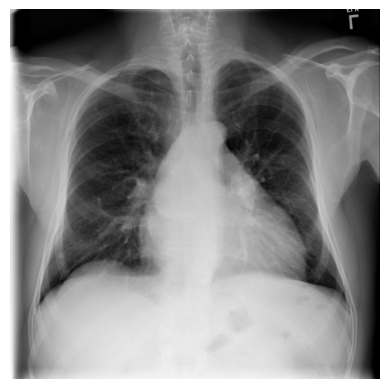

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from src.data.nih import load_labels, find_images
from src.data.dicom_io import png_to_dicom, load_dicom, to_display

df = load_labels('../data/raw/nih/Data_Entry_2017.csv')
df["path"]  = df["image_index"].map(find_images('/Users/dr_bolty/ai_diag/data/raw/nih/'))

row = df.iloc[0]

out = "../data/interim/test_00000001_000.dcm"
png_to_dicom(row["path"], row, out)

img, meta = load_dicom(out)

original = np.array(Image.open(row["path"]).convert("L"))

print("pixels identical:", np.array_equal(img.astype(np.uint8), original))
print(meta)
print(row[["patient_id", "patient_sex", "patient_age", "view_position"]])

plt.imshow(to_display(img), cmap="gray"); plt.axis("off"); plt.show()


finding_labels
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

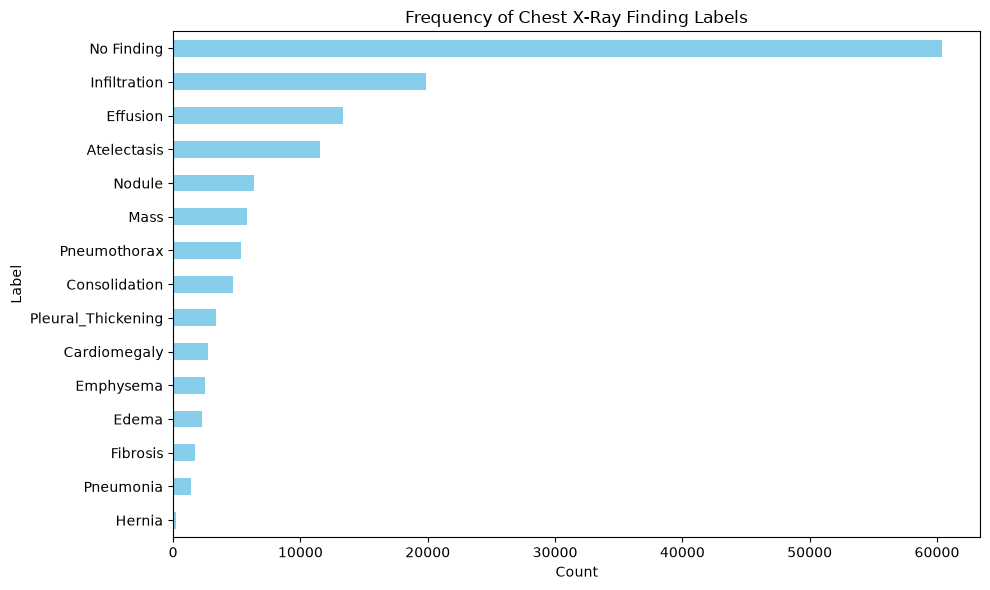

In [4]:
#Label Frequencies
label_counts = df["finding_labels"].str.split("|").explode().value_counts()
print (label_counts)

plt.figure(figsize=(10,6))
label_counts.sort_values().plot(kind="barh", color="skyblue")
plt.title("Frequency of Chest X-Ray Finding Labels")
plt.xlabel("Count")
plt.ylabel("Label")
plt.tight_layout()
plt.show

count    30805.000000
mean         3.639669
std          7.266734
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        184.000000
dtype: float64


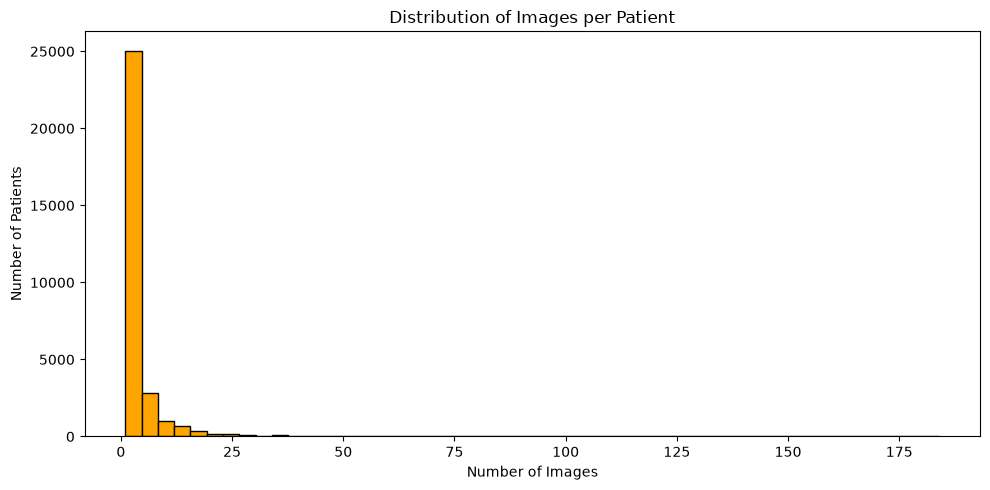

In [6]:
#Images per patient

patient_counts = df.groupby("patient_id").size()
print(patient_counts.describe())

plt.figure(figsize=(10,5))
patient_counts.plot(kind="hist", bins=50, color="orange", edgecolor="black")
plt.title("Distribution of Images per Patient")
plt.xlabel("Number of Images")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

In [10]:
#Noise Data

print(df["patient_age"].describe())

impossible_age_count = (df["patient_age"] > 100).sum()
print(f"\nNumber of images with patient age > 100 : {impossible_age_count}")

count    112120.000000
mean         46.901463
std          16.839923
min           1.000000
25%          35.000000
50%          49.000000
75%          59.000000
max         414.000000
Name: patient_age, dtype: float64

Number of images with patient age > 100 : 16


In [17]:
#More Info

patient_sex_breakdown = (df["patient_sex"].value_counts())
print(f"Patient Sex: {patient_sex_breakdown}")

view_position_breakdown = (df["view_position"].value_counts())
print(f"\n\nView Position: {view_position_breakdown}")

df["has_findings"] = df["finding_labels"] != "No Finding"
finding_share_by_view = df.groupby("view_position")["has_findings"].mean()

print(f"\n\nShare of Images with Findings by View Position: {finding_share_by_view}")

Patient Sex: patient_sex
M    63340
F    48780
Name: count, dtype: int64


View Position: view_position
PA    67310
AP    44810
Name: count, dtype: int64


Share of Images with Findings by View Position: view_position
AP    0.530038
PA    0.416105
Name: has_findings, dtype: float64


In [21]:
from pathlib import Path

train_val_names = Path("../data/raw/nih/train_val_list.txt").read_text().split()
test_names = Path("../data/raw/nih/test_list.txt").read_text().split()

df_train_val = df[df["image_index"].isin(train_val_names)]
df_test = df[df["image_index"].isin(test_names)]


train_patients = set(df_train_val["patient_id"])
test_patients = set(df_test["patient_id"])

leakage = train_patients & test_patients
print(f"Number of overlapping patients between train/val and test: {len(leakage)}")


Number of overlapping patients between train/val and test: 0
